<a href="https://colab.research.google.com/github/sachin23-an/quant-researcher-practical-lab/blob/main/Quant_Researcher_Practical_Lab_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quant Researcher — Practical Lab 6
### Portfolio Construction at Scale & Risk Management — Part 8D + Part 11 ka practical version


In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.optimize import minimize
np.random.seed(44)
plt.rcParams['figure.figsize']=(8,4)


## 0. Data — synthetic multi-asset return panel

6 "stocks", realistic correlation structure, taaki optimizer ke paas kuch meaningful cheez optimize karne ko ho.


In [2]:
n_assets, n_days = 6, 500
names = ['BANK','IT','PHARMA','AUTO','ENERGY','FMCG']
common = np.random.randn(n_days)*0.008
rets = pd.DataFrame(index=range(n_days))
for name in names:
    idio = np.random.randn(n_days)*np.random.uniform(0.008,0.018)
    loading = np.random.uniform(0.3,0.9)
    rets[name] = loading*common + idio

mu = rets.mean()*252
cov = rets.cov()*252
print('Annualized expected returns:'); print(mu.round(3))


Annualized expected returns:
BANK     -0.169
IT        0.035
PHARMA   -0.059
AUTO      0.044
ENERGY    0.004
FMCG     -0.080
dtype: float64


## A. Portfolio Construction at Scale — Mean-Variance Optimization (with real constraints)

Textbook Markowitz unconstrained optimize karta hai — real portfolios mein turnover limits, no-short, per-asset caps hote hain. Constraints ke saath optimize karte hain.


In [3]:
def portfolio_vol(w, cov): return np.sqrt(w @ cov @ w)
def portfolio_ret(w, mu):   return w @ mu

def max_sharpe_portfolio(mu, cov, max_weight=0.35, long_only=True):
    n = len(mu)
    def neg_sharpe(w):
        return -portfolio_ret(w, mu) / portfolio_vol(w, cov)
    constraints = [{'type':'eq', 'fun': lambda w: w.sum() - 1}]
    bounds = [(0, max_weight) if long_only else (-max_weight, max_weight) for _ in range(n)]
    w0 = np.ones(n)/n
    result = minimize(neg_sharpe, w0, bounds=bounds, constraints=constraints, method='SLSQP')
    return pd.Series(result.x, index=mu.index), result.success

weights, ok = max_sharpe_portfolio(mu, cov, max_weight=0.35)
print('Optimized weights (max 35% per asset):')
print(weights.round(3))
print(f'Portfolio expected return: {portfolio_ret(weights, mu):.1%}  vol: {portfolio_vol(weights, cov):.1%}')


Optimized weights (max 35% per asset):
BANK      0.00
IT        0.35
PHARMA    0.00
AUTO      0.35
ENERGY    0.30
FMCG      0.00
dtype: float64
Portfolio expected return: 2.9%  vol: 12.5%


In [4]:
# Covariance shrinkage (Ledoit-Wolf) -- fixes the noisy-covariance-matrix problem
from sklearn.covariance import LedoitWolf

lw = LedoitWolf().fit(rets)
cov_shrunk = pd.DataFrame(lw.covariance_, index=rets.columns, columns=rets.columns) * 252

weights_raw, _    = max_sharpe_portfolio(mu, cov, max_weight=0.35)
weights_shrunk, _ = max_sharpe_portfolio(mu, cov_shrunk, max_weight=0.35)

compare = pd.DataFrame({'raw_cov_weights': weights_raw, 'shrunk_cov_weights': weights_shrunk})
print(compare.round(3))
print('\nShrinkage intensity used:', round(lw.shrinkage_, 3))


        raw_cov_weights  shrunk_cov_weights
BANK               0.00                0.00
IT                 0.35                0.35
PHARMA             0.00                0.00
AUTO               0.35                0.35
ENERGY             0.30                0.30
FMCG               0.00                0.00

Shrinkage intensity used: 0.052


**Kyun shrinkage:** raw sample covariance matrix, especially kam data (few years, many assets) ke saath, bahut noisy hoti hai — optimizer us noise ko "edge" samajh ke extreme weights de deta hai. Ledoit-Wolf shrinkage covariance ko ek structured target (jaise identity/constant-correlation) ki taraf thoda khinchta hai — isse weights zyada stable aur realistic aate hain. Interview follow-up jo bahut common hai: "your covariance matrix is estimated from 2 years of daily data for 500 stocks — what's wrong with that?" — yahi jawab hai.


## Risk Parity — equal RISK contribution, equal CAPITAL nahi


In [5]:
def risk_contribution(w, cov):
    port_vol = portfolio_vol(w, cov)
    marginal_contrib = cov @ w / port_vol
    return w * marginal_contrib

def risk_parity_weights(cov):
    n = len(cov)
    def objective(w):
        rc = risk_contribution(w, cov.values)
        target = rc.mean()
        return np.sum((rc - target)**2)
    constraints = [{'type':'eq', 'fun': lambda w: w.sum()-1}]
    bounds = [(0.001, 1) for _ in range(n)]
    result = minimize(objective, np.ones(n)/n, bounds=bounds, constraints=constraints, method='SLSQP')
    return pd.Series(result.x, index=cov.columns)

rp_weights = risk_parity_weights(cov)
rp_risk_contrib = pd.Series(risk_contribution(rp_weights.values, cov.values), index=cov.columns)
print('Risk-parity weights:'); print(rp_weights.round(3))
print('\nRisk contribution per asset (should be roughly EQUAL):')
print((rp_risk_contrib / rp_risk_contrib.sum()).round(3))


Risk-parity weights:
BANK      0.143
IT        0.126
PHARMA    0.113
AUTO      0.220
ENERGY    0.204
FMCG      0.194
dtype: float64

Risk contribution per asset (should be roughly EQUAL):
BANK      0.164
IT        0.162
PHARMA    0.167
AUTO      0.158
ENERGY    0.169
FMCG      0.179
dtype: float64


## Part 11 — Risk Management

**A-D: Risk types, sizing for survival, stop-loss vs probabilistic.** Position-level stop-loss ek hard rule hai; probabilistic risk (VaR/CVaR) ek distribution-based view hai. Dono saath use hote hain.


In [6]:
def fixed_fractional_sizing(capital, risk_per_trade_pct, stop_loss_pct):
    """Kitna position lena chahiye agar har trade pe sirf risk_per_trade_pct capital risk karna hai."""
    risk_amount = capital * risk_per_trade_pct
    position_size = risk_amount / stop_loss_pct
    return position_size

capital = 1_000_000
for risk_pct, stop_pct in [(0.01, 0.02), (0.01, 0.05), (0.02, 0.02)]:
    size = fixed_fractional_sizing(capital, risk_pct, stop_pct)
    print(f'risk/trade={risk_pct:.0%}, stop-loss={stop_pct:.0%}  -> position size: Rs.{size:,.0f}')


risk/trade=1%, stop-loss=2%  -> position size: Rs.500,000
risk/trade=1%, stop-loss=5%  -> position size: Rs.200,000
risk/trade=2%, stop-loss=2%  -> position size: Rs.1,000,000


## E. Risk Limits, Drawdown Control & the Kill Switch

Equity curve pe running max drawdown track karna, aur ek rule-based kill-switch jo size kam karta hai jab drawdown threshold cross ho.


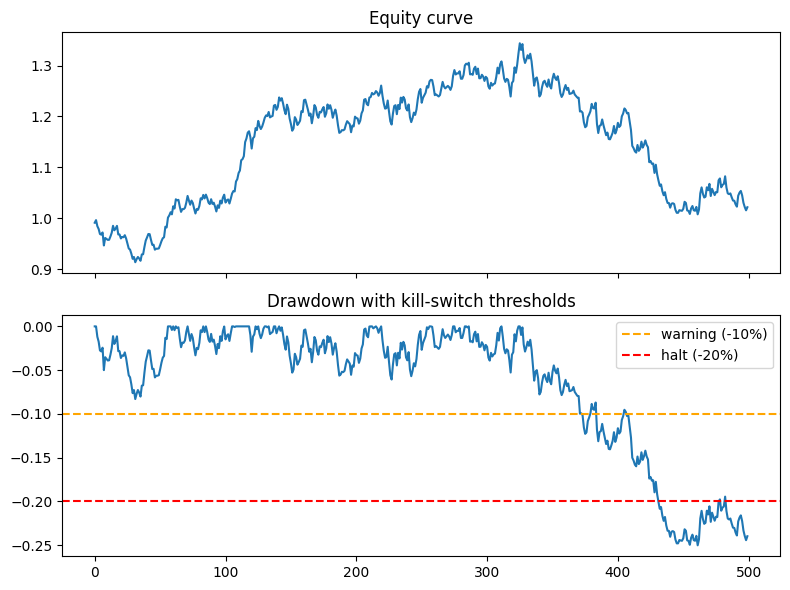

Days at half-size: 53  Days halted: 67


In [7]:
def running_drawdown(cum_returns):
    running_max = cum_returns.cummax()
    return (cum_returns - running_max) / running_max

def kill_switch_sizing(cum_returns, dd_warning=-0.10, dd_halt=-0.20):
    dd = running_drawdown(cum_returns)
    size_multiplier = pd.Series(1.0, index=cum_returns.index)
    size_multiplier[dd < dd_warning] = 0.5   # cut size in half
    size_multiplier[dd < dd_halt]    = 0.0   # stop trading entirely
    return dd, size_multiplier

strategy_returns = pd.Series(np.random.randn(500)*0.01 - 0.0003)  # slightly negative-drift toy strategy
cum = (1+strategy_returns).cumprod()
dd, sizing = kill_switch_sizing(cum)

fig, axes = plt.subplots(2,1, figsize=(8,6), sharex=True)
cum.plot(ax=axes[0], title='Equity curve')
dd.plot(ax=axes[1], title='Drawdown with kill-switch thresholds')
axes[1].axhline(-0.10, color='orange', ls='--', label='warning (-10%)')
axes[1].axhline(-0.20, color='red', ls='--', label='halt (-20%)')
axes[1].legend()
plt.tight_layout(); plt.show()

print('Days at half-size:', (sizing==0.5).sum(), ' Days halted:', (sizing==0.0).sum())


## F/G. Portfolio-Level Risk & Tail Risk

Poore portfolio ka VaR/CVaR nikalte hain (not just one asset), aur dekhte hain diversification kitna risk reduce karta hai vs naive sum.


In [8]:
def portfolio_historical_var(returns_df, weights, alpha=0.05):
    port_returns = returns_df @ weights
    return -np.percentile(port_returns, alpha*100), port_returns

port_var, port_returns = portfolio_historical_var(rets, weights)
standalone_vars = [-np.percentile(rets[a], 5) for a in rets.columns]
naive_sum_var = sum(w*v for w, v in zip(weights, standalone_vars))

print(f'Portfolio VaR (diversified)     : {port_var:.4f}')
print(f'Naive weighted-sum of asset VaRs: {naive_sum_var:.4f}')
print(f'Diversification benefit         : {(1 - port_var/naive_sum_var):.1%} risk reduction')


Portfolio VaR (diversified)     : 0.0125
Naive weighted-sum of asset VaRs: 0.0196
Diversification benefit         : 36.1% risk reduction


**Yahi hai diversification ka quantified proof** — portfolio VaR individual VaRs ke weighted sum se kam hota hai jab tak assets perfectly correlated na hon (correlation < 1).


## Wrap-up — saare 6 labs ka full picture

Lab 1: foundations + alpha + honest backtesting
Lab 2: regime classification + leakage audit
Lab 3: options, Greeks, VaR, stress testing
Lab 4: microstructure, execution, Kelly sizing
Lab 5: ARIMA, deflated Sharpe, PCA, Kalman, meta-labeling, frac diff, purged CV
Lab 6: portfolio construction (with shrinkage + risk parity) + drawdown/kill-switch risk management

Ab theory file ka har major quantitative topic ek baar khud code karke dekha ja chuka hai — agli baar koi interviewer "live mein karke dikhao" bole to structure already muscle memory mein hai.
